Q1 create a python code relateed to liquid phase reactor for rxn a+b=c reversible intial conc is [a] knot equals to 1 [b]=1 [c] = 0 mol/L if x= mol/L of c form kc =x/(1-x)^ 2which changes to kc-x^2-(2kc+1)-x+kc

 Display both roots, equilibrium concentrations, and percent conversion to three decimal places. Classify conversion as High (at least 70%), Moderate (at least 40%), or Low. Test with `4`, `0.5`, `abc`, and `-2`.

In [15]:
import math

try:
    kc = float(input("Enter the equilibrium constant Kc: "))
except ValueError:
    print("Invalid input: Kc must be a number.")
else:
    if not math.isfinite(kc) or kc <= 0:
        print("Invalid input: Kc must be a finite number greater than 0.")
    else:
        # Kc*x^2 - (2*Kc + 1)*x + Kc = 0
        a = kc
        b = -(2 * kc + 1)
        c = kc

        discriminant = b**2 - 4 * a * c
        print(f"a = {a:.3f}, b = {b:.3f}, c = {c:.3f}")
        print(f"Discriminant = {discriminant:.3f}")

        if discriminant < 0:
            print("No real roots found.")
        else:
            root_1 = (-b + math.sqrt(discriminant)) / (2 * a)
            root_2 = (-b - math.sqrt(discriminant)) / (2 * a)

            print(f"Root 1 = {root_1:.3f}")
            print(f"Root 2 = {root_2:.3f}")

            valid_roots = [root for root in (root_1, root_2) if 0 <= root <= 1]

            if not valid_roots:
                print("No physically meaningful root found in the range 0 <= x <= 1.")
            else:
                x = valid_roots[0]

                initial_a = 1.0
                initial_b = 1.0
                initial_c = 0.0

                equilibrium_a = initial_a - x
                equilibrium_b = initial_b - x
                equilibrium_c = initial_c + x

                conversion = (x / initial_a) * 100

                print(f"\nMeaningful root, x = {x:.3f} mol/L")
                print(f"[A] at equilibrium = {equilibrium_a:.3f} mol/L")
                print(f"[B] at equilibrium = {equilibrium_b:.3f} mol/L")
                print(f"[C] at equilibrium = {equilibrium_c:.3f} mol/L")
                print(f"Conversion = {conversion:.3f}%")

                if conversion >= 70:
                    print("Conversion classification: High")
                elif conversion >= 40:
                    print("Conversion classification: Moderate")
                else:
                    print("Conversion classification: Low")

Invalid input: Kc must be a finite number greater than 0.


Q2 Part A generate abegineer friendly phython code for batch reactor simulation and batch tracking here reactant A gets decompose to products by 1st order rxn dC/dt=-Kc use euler method c_new=c_old-k.c_old *delta t take C knot = 2 mol/L  k= 0.08 min -1 delta t= 1 min display simulate table for 10 mins  of time(min), concentration(mol/L), CONVERSION (%) USING FOR LOOP  then use math.exp() to calculate C knot e^(-Kc) at 10 mn display absolute error of euler result using while repeat conversion until 60% or time 100 mins also display the time needed for final concentration 

In [5]:
import math

# Initial conditions and simulation settings
c0 = 2.0       # Initial concentration of A (mol/L)
k = 0.08       # Rate constant (min^-1)
dt = 1.0       # Time step (min)

time = 0
concentration = c0

print("Euler method simulation")
print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

# Print the initial values at time zero
conversion = (c0 - concentration) / c0 * 100
print(f"{time:10.0f} {concentration:24.3f} {conversion:18.3f}")

# Simulate and display the first 10 minutes
for step in range(1, 11):
    concentration = concentration - k * concentration * dt
    time = step
    conversion = (c0 - concentration) / c0 * 100
    print(f"{time:10.0f} {concentration:24.3f} {conversion:18.3f}")

# Calculate the exact concentration at 10 minutes
exact_concentration = c0 * math.exp(-k * time)
absolute_error = abs(exact_concentration - concentration)

print(f"\nExact concentration at {time} min: {exact_concentration:.3f} mol/L")
print(f"Absolute error at {time} min: {absolute_error:.3f} mol/L")

# Continue until conversion reaches 60% or time reaches 100 minutes
while conversion < 60 and time < 100:
    concentration = concentration - k * concentration * dt
    time += dt
    conversion = (c0 - concentration) / c0 * 100

print("\nFinal result")
print(f"Time: {time:.0f} min")
print(f"Concentration: {concentration:.3f} mol/L")
print(f"Conversion: {conversion:.3f}%")

if conversion >= 60:
    print("The 60% conversion target was reached.")
else:
    print("The 60% conversion target was not reached within 100 minutes.")

Euler method simulation
Time (min)    Concentration (mol/L)     Conversion (%)
         0                    2.000              0.000
         1                    1.840              8.000
         2                    1.693             15.360
         3                    1.557             22.131
         4                    1.433             28.361
         5                    1.318             34.092
         6                    1.213             39.364
         7                    1.116             44.215
         8                    1.026             48.678
         9                    0.944             52.784
        10                    0.869             56.561

Exact concentration at 10 min: 0.899 mol/L
Absolute error at 10 min: 0.030 mol/L

Final result
Time: 11 min
Concentration: 0.799 mol/L
Conversion: 60.036%
The 60% conversion target was reached.


Q2 Part B generate begineer friendly program for batch tracking reads label loops through each character display no of digits and sum of digits clearly shows msg for empty label or no digits 

In [16]:
label = input("Enter the batch label: ")

if label.strip() == "":
    print("The batch label is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in label:
        if character in "0123456789":
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The batch label contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


Number of digits: 8
Sum of digits: 14


Q 3 Part A Generate a recursive function factorial (n) where order does not matter n candidate is present out test r together in formulation here we have to consider the base case for 0! & fuction combination (n,r)=n!/(r!(n-r)!) invalid values r>n dislay for n=6 r=3 show text for n=5 r=7

In [8]:
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is only defined for non-negative integers.")

    # Base case: 0! and 1! are both 1
    if n == 0 or n == 1:
        return 1

    # Recursive case
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        print("Invalid input: n and r must be non-negative.")
        return

    if r > n:
        print(f"Invalid input: r ({r}) cannot be greater than n ({n}).")
        return

    ways = factorial(n) // (factorial(r) * factorial(n - r))
    print(f"Choosing {r} from {n} candidates gives {ways} combinations.")


combination(6, 3)
combination(5, 7)

Choosing 3 from 6 candidates gives 20 combinations.
Invalid input: r (7) cannot be greater than n (5).


Q3 Part B generate a iterative function fib_iter(n) which returns list of first n fibonacci number and recursive function fib_rec(k) returns K fibonaaci no (F0 =0,F1=1)  for condition samples taken at times= fibonacci no *2 min dislpay a table of sample no fibonacci tag sampling tag in mins for n =10

In [9]:
def fib_iter(n):
    """Return a list containing the first n Fibonacci numbers."""
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    first = 0
    second = 1

    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second

    return numbers


def fib_rec(k):
    """Return the Fibonacci number at position k, where F0 = 0 and F1 = 1."""
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1

    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_numbers = fib_iter(n)

print("First", n, "Fibonacci numbers:", fibonacci_numbers)
print()
print(f"{'Sample no.':<12}{'Fibonacci tag':<20}{'Sampling time (min)':<20}")

for sample_number in range(1, n + 1):
    k = sample_number - 1
    fibonacci_tag = fib_rec(k)
    sampling_time = fibonacci_tag * 2

    print(f"{sample_number:<12}F{k} = {fibonacci_tag:<16}{sampling_time:<20}")

First 10 Fibonacci numbers: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]

Sample no.  Fibonacci tag       Sampling time (min) 
1           F0 = 0               0                   
2           F1 = 1               2                   
3           F2 = 1               2                   
4           F3 = 2               4                   
5           F4 = 3               6                   
6           F5 = 5               10                  
7           F6 = 8               16                  
8           F7 = 13              26                  
9           F8 = 21              42                  
10          F9 = 34              68                  


Q 4 **Prompt:**

Write beginner-friendly Python code using pandas, NumPy, and Matplotlib for two datasets. For ester hydrolysis, use times `[0, 10, 20, 30, 40, 50]` min, Run 1 `[1.00, 0.74, 0.55, 0.41, 0.30, 0.22]` mol/L, and Run 2 `[1.00, 0.61, 0.37, 0.22, 0.14, 0.08]` mol/L. Save as `kinetics.csv` without an index and `kinetics.json`, read the CSV back, display its shape and data types, calculate each run’s mean and standard deviation, identify which run varies more, and plot both runs together with a title, labeled axes with units, legend, and grid. For nitrogen at constant temperature, use volumes `[1, 2, 3, 4, 5]` L and pressures `[4.00, 2.03, 1.31, 1.02, 0.81]` bar; calculate mean Kfrom P*V THEN MAKE A SCATTER PLOT WITH REFERENCE CURVE p=k/v title,labelled axes with units and legends and grid

Ester hydrolysis data
Shape: (6, 3)

Data types:
Time_min               int64
Run1_low_T_mol_L     float64
Run2_high_T_mol_L    float64
dtype: object

Mean concentration (mol/L):
Run1_low_T_mol_L     0.536667
Run2_high_T_mol_L    0.403333
dtype: float64

Standard deviation (mol/L):
Run1_low_T_mol_L     0.292757
Run2_high_T_mol_L    0.348521
dtype: float64
Run 2 has more variation.


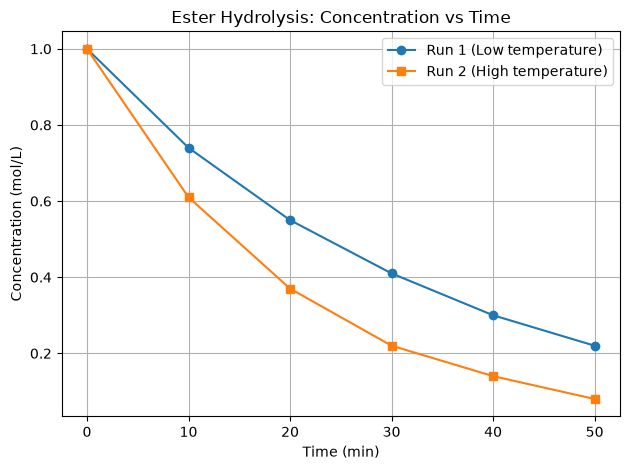


Nitrogen gas data
   Volume_L  Pressure_bar
0         1          4.00
1         2          2.03
2         3          1.31
3         4          1.02
4         5          0.81

Mean K = 4.024 L·bar


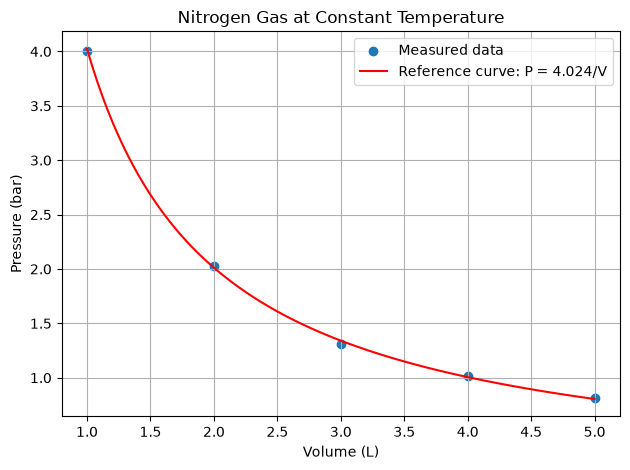

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Part 1: Ester hydrolysis data
kinetics_data = {
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_low_T_mol_L": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_high_T_mol_L": [1.00, 0.61, 0.37, 0.22, 0.14, 0.08],
}

kinetics_df = pd.DataFrame(kinetics_data)

# Save the ester data, then read the CSV back
kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=4)
kinetics = pd.read_csv("kinetics.csv")

print("Ester hydrolysis data")
print("Shape:", kinetics.shape)
print("\nData types:")
print(kinetics.dtypes)

run_columns = ["Run1_low_T_mol_L", "Run2_high_T_mol_L"]

print("\nMean concentration (mol/L):")
print(kinetics[run_columns].mean())

standard_deviations = kinetics[run_columns].std()
print("\nStandard deviation (mol/L):")
print(standard_deviations)

if standard_deviations["Run1_low_T_mol_L"] > standard_deviations["Run2_high_T_mol_L"]:
    print("Run 1 has more variation.")
else:
    print("Run 2 has more variation.")

# Plot both ester runs
plt.figure()
plt.plot(
    kinetics["Time_min"],
    kinetics["Run1_low_T_mol_L"],
    marker="o",
    label="Run 1 (Low temperature)",
)
plt.plot(
    kinetics["Time_min"],
    kinetics["Run2_high_T_mol_L"],
    marker="s",
    label="Run 2 (High temperature)",
)
plt.title("Ester Hydrolysis: Concentration vs Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Part 2: Nitrogen gas at constant temperature
nitrogen_data = {
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [4.00, 2.03, 1.31, 1.02, 0.81],
}

nitrogen_df = pd.DataFrame(nitrogen_data)

# Calculate K as the mean of P * V
k_pv = (nitrogen_df["Pressure_bar"] * nitrogen_df["Volume_L"]).mean()

print("\nNitrogen gas data")
print(nitrogen_df)
print(f"\nMean K = {k_pv:.3f} L·bar")

# Calculate the reference curve P = K / V
volume_curve = np.linspace(
    nitrogen_df["Volume_L"].min(),
    nitrogen_df["Volume_L"].max(),
    100,
)
pressure_curve = k_pv / volume_curve

# Plot measured points and the reference curve
plt.figure()
plt.scatter(
    nitrogen_df["Volume_L"],
    nitrogen_df["Pressure_bar"],
    label="Measured data",
)
plt.plot(
    volume_curve,
    pressure_curve,
    color="red",
    label=f"Reference curve: P = {k_pv:.3f}/V",
)
plt.title("Nitrogen Gas at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()